> **Clear all outputs before committing**: tiles, paths and slide
> identifiers must not end up in the repository.

# PROiFHESi training augmentations

Visual check of every augmentation built by
`finetuning.dataloader.build_augmentations`, with the parameters of the
configuration (parser defaults < YAML < `OVERRIDES`). Augmentations are
applied on the raw uint8 tile, before the encoder transform (center crop to
`img_size`, normalisation).

1. **Setup**
2. **Configuration**
3. **Tiles**: a random sample of `img_dir`
4. **Catalogue**: each transform of the pipeline alone (p = 1)
5. **Spatial**: the 8 flip / rot90 orientations (targets unchanged)
6. **HED stain jitter**: decomposition, background threshold, `sigma_alpha`
   and `sigma_beta` sweeps, realism against the cohort color distribution
7. **Training pipeline**: random draws with the configured probabilities

Nothing is written to disk.

## 1. Setup

In [1]:
from __future__ import annotations

# General libraries
import random
import sys
from argparse import Namespace
from pathlib import Path

# Data libraries
import albumentations as A
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

# Repository root on the path (first parent holding `finetuning/`)
REPO_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents) if (path / "finetuning").is_dir()
)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

# Project modules
from finetuning.arguments import (
    AUGMENTATION_PROBABILITIES,
    build_parser,
    load_yaml_config,
)
from finetuning.dataloader import HEDStainAugment, build_augmentations

/cluster/CBIO/home/mblons/miniconda3/envs/cpath_py310/lib/python3.10/site-packages/albumentations/__init__.py:24: UserWarning: A new version of Albumentations is available: 2.0.8 (you have 1.4.21). Upgrade using: pip install -U albumentations. To disable automatic update checks, set the environment variable NO_ALBUMENTATIONS_UPDATE to 1.
  check_for_updates()
/cluster/CBIO/home/mblons/miniconda3/envs/cpath_py310/lib/python3.10/site-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (2.3.0) or chardet (6.0.0.post1)/charset_normalizer (3.4.1) doesn't match a supported version!
  warnings.warn(


In [2]:
def load_tile(path: Path) -> np.ndarray:
    """Read a tile as a uint8 RGB array (as `HETileDataset` does)."""
    return np.asarray(Image.open(path).convert("RGB"))


def seed_everything(seed: int) -> None:
    """Seed the generators used by albumentations 1.4 and numpy."""
    random.seed(seed)
    np.random.seed(seed)


def show_grid(rows, row_titles=None, column_titles=None, size=2.6, suptitle=None):
    """Display a list of rows of images (HWC arrays) as a grid."""
    n_rows = len(rows)
    n_columns = max(len(row) for row in rows)
    fig, axes = plt.subplots(
        n_rows,
        n_columns,
        figsize=(size * n_columns, size * n_rows),
        layout="constrained",
        squeeze=False,
    )
    for axis in axes.flat:
        axis.set_axis_off()
    for row_index, row in enumerate(rows):
        for column_index, image in enumerate(row):
            axis = axes[row_index, column_index]
            axis.imshow(image, cmap="gray" if image.ndim == 2 else None)
            if row_index == 0 and column_titles is not None:
                axis.set_title(column_titles[column_index], fontsize=9)
        if row_titles is not None:
            axes[row_index, 0].set_axis_on()
            axes[row_index, 0].set_xticks([])
            axes[row_index, 0].set_yticks([])
            axes[row_index, 0].set_ylabel(row_titles[row_index], fontsize=9)
    if suptitle is not None:
        fig.suptitle(suptitle, fontsize=11)
    plt.show()


def difference_map(original: np.ndarray, augmented: np.ndarray, gain: float = 10.0):
    """Absolute difference (mean over RGB), amplified for display."""
    difference = np.abs(augmented.astype(np.float32) - original.astype(np.float32))
    return np.clip(gain * difference.mean(axis=-1), 0, 255).astype(np.uint8)


def mean_absolute_difference(original: np.ndarray, augmented: np.ndarray) -> float:
    """Mean absolute pixel difference, in grey levels."""
    return float(np.abs(augmented.astype(np.float32) - original.astype(np.float32)).mean())


def stain_concentrations(image: np.ndarray, od_threshold: float):
    """
    H / E / DAB concentrations (H, W, 3) and tissue mask (H, W), with the
    same optical density and stain matrix as `HEDStainAugment`.
    """
    pixels = image.reshape(-1, 3).astype(np.float32)
    optical_density = -np.log((pixels + 1.0) / 256.0)
    concentrations = optical_density @ HEDStainAugment.OD_TO_STAIN
    tissue = optical_density.max(axis=1) > od_threshold
    return (
        concentrations.reshape(image.shape),
        tissue.reshape(image.shape[:2]),
    )


def hed_jitter(image: np.ndarray, alpha, beta=(0.0, 0.0), od_threshold=0.15):
    """Deterministic HED jitter with given (alpha_H, alpha_E), (beta_H, beta_E)."""
    transform = HEDStainAugment(od_threshold=od_threshold, p=1.0)
    return transform.apply(
        image,
        alpha=np.asarray(alpha, dtype=np.float32),
        beta=np.asarray(beta, dtype=np.float32),
    )

## 2. Configuration

Same precedence as `finetuning.arguments.get_arguments` for the augmentation
options: parser defaults < YAML (`CONFIG_PATH`) < `OVERRIDES`.
Set `p_hed > 0` in `OVERRIDES` to preview the HED jitter inside the full
training pipeline (section 7).

In [20]:
IMG_DIR = Path("/cluster/CBIO/data1/mblons/projects/PROiFHESi/data/ORION/20012026/CRC_TILE_SIGNATURE/tile_feat_20x_345px_0px_overlap/tile_0.5_mpp")  # holds tile images (*.jpeg)
CONFIG_PATH = None  # optional YAML, e.g. Path("<configs/config_lora_variant.yaml>")
OVERRIDES = {
    "p_hed": 0.5,
    "hed_sigma_alpha": 0.2,
    "hed_sigma_beta":0.05,
}

N_TILES = 4  # tiles shown in each grid
N_DRAWS = 5  # random draws per transform
N_COHORT_TILES = 500  # tiles used for the cohort color distribution (6.2, 6.5)
SEED = 0

parser = build_parser()
if CONFIG_PATH is not None:
    parser.set_defaults(**load_yaml_config(CONFIG_PATH))
args = parser.parse_args([])
for name, value in OVERRIDES.items():
    setattr(args, name, value)

AUGMENTATION_ARGUMENTS = (
    "augment",
    *AUGMENTATION_PROBABILITIES,
    "hed_sigma_alpha",
    "hed_sigma_beta",
    "hed_od_threshold",
)
pd.Series({name: getattr(args, name) for name in AUGMENTATION_ARGUMENTS}, name="value").to_frame()

,value
augment,True
p_hflip,0.5
p_vflip,0.5
p_rotate90,0.5
p_hed,0.5
p_brightness_contrast,0.5
p_blur,0.1
p_sharpen,0.1
p_noise,0.1
p_compression,0.1


## 3. Tiles

644239 *.jpeg tiles in img_dir
tile shape: (224, 224, 3) uint8


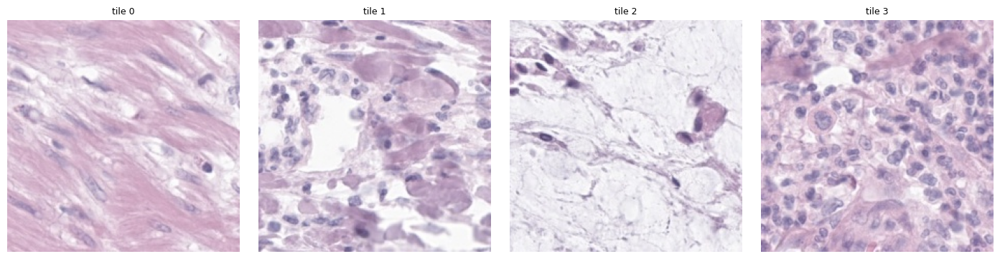

In [4]:
tile_paths = sorted(IMG_DIR.glob(f"*.{args.img_format}"))
print(f"{len(tile_paths)} *.{args.img_format} tiles in img_dir")

rng = np.random.default_rng(SEED)
sample_paths = [tile_paths[i] for i in rng.choice(len(tile_paths), N_TILES, replace=False)]
tiles = [load_tile(path) for path in sample_paths]
print("tile shape:", tiles[0].shape, tiles[0].dtype)

show_grid(
    [tiles],
    column_titles=[f"tile {i}" for i in range(N_TILES)],
    size=3.5,
)

## 4. Catalogue: each transform alone

Every transform of the pipeline built with all probabilities set to 1
(`p_hed` included), so the parameters are exactly those of training. Rows are
tiles, columns are independent draws; the last column is the amplified
(x10) absolute difference of the last draw, which makes blur and noise
visible. The title gives the mean absolute difference over draws (grey
levels).

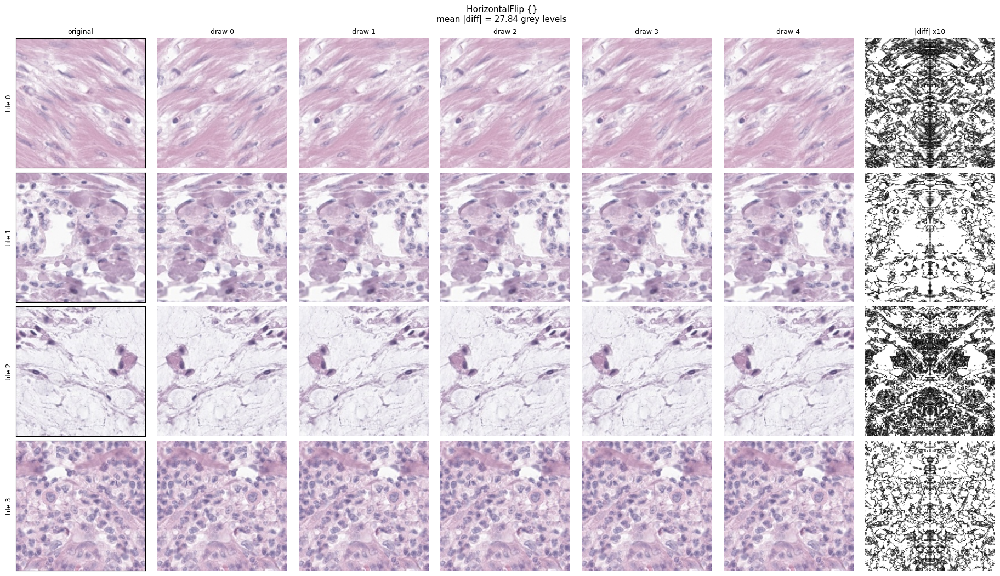

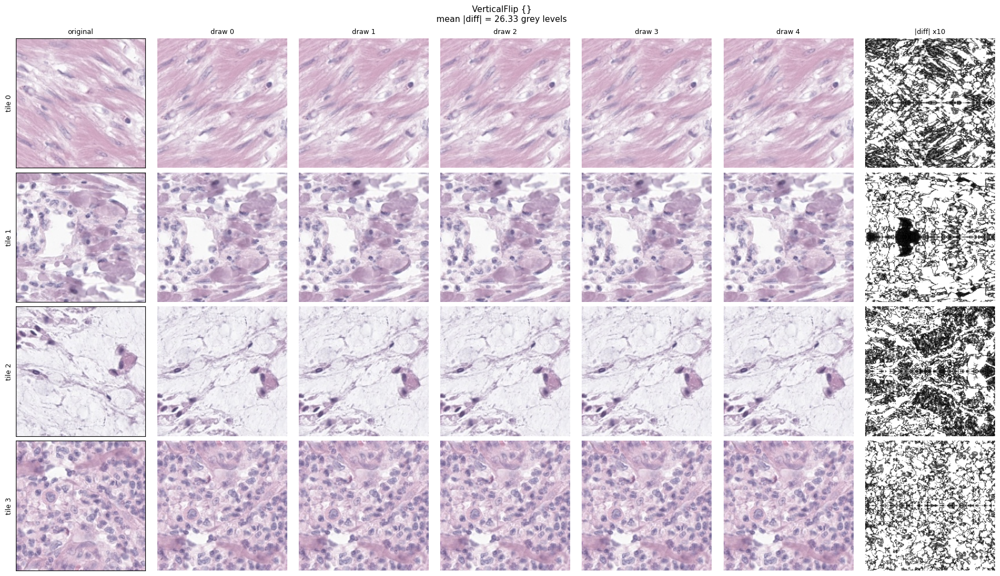

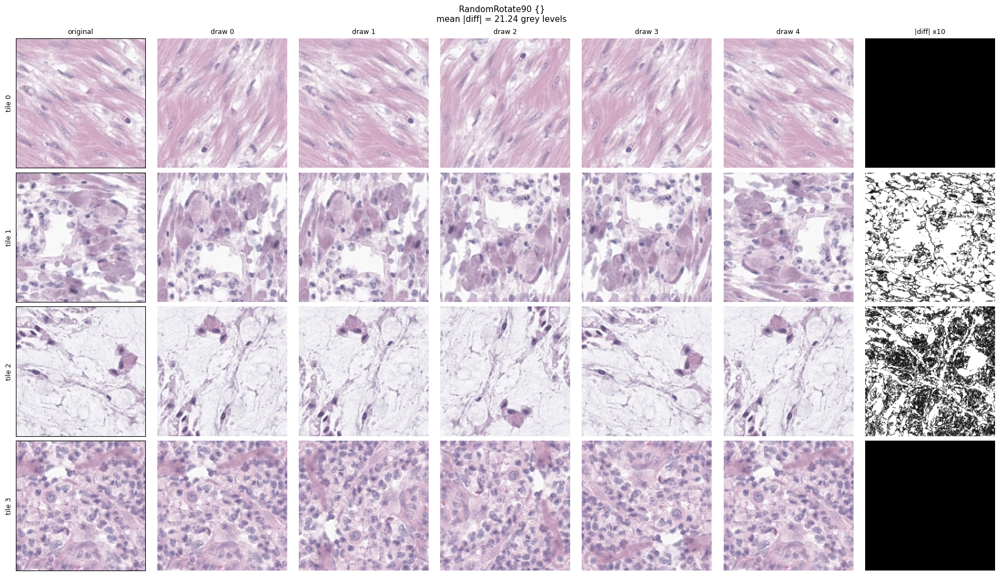

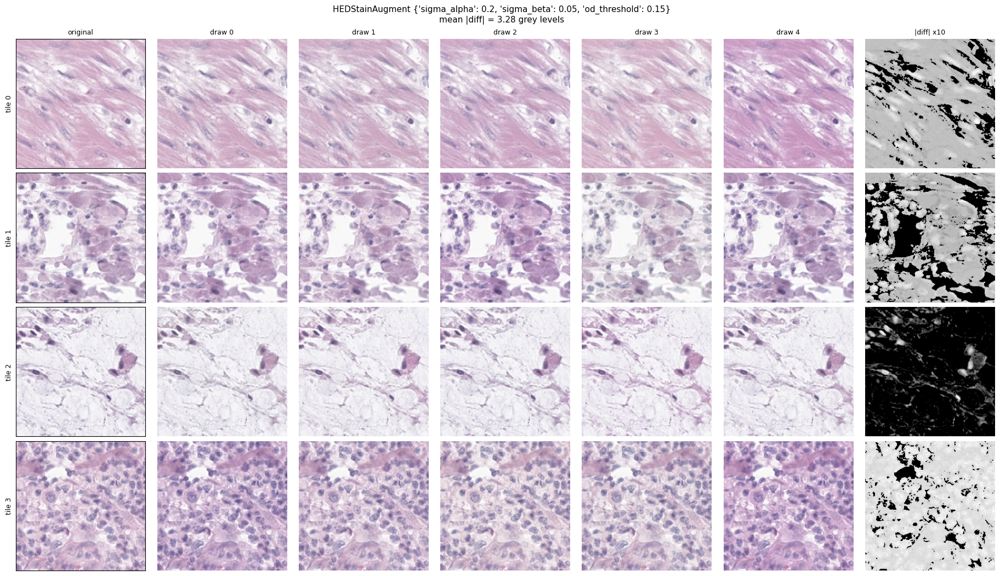

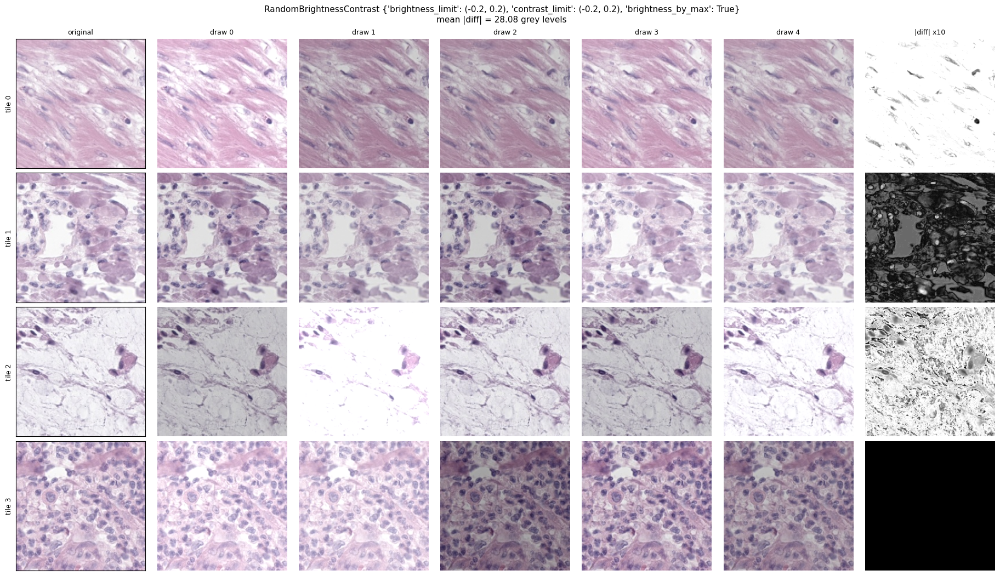

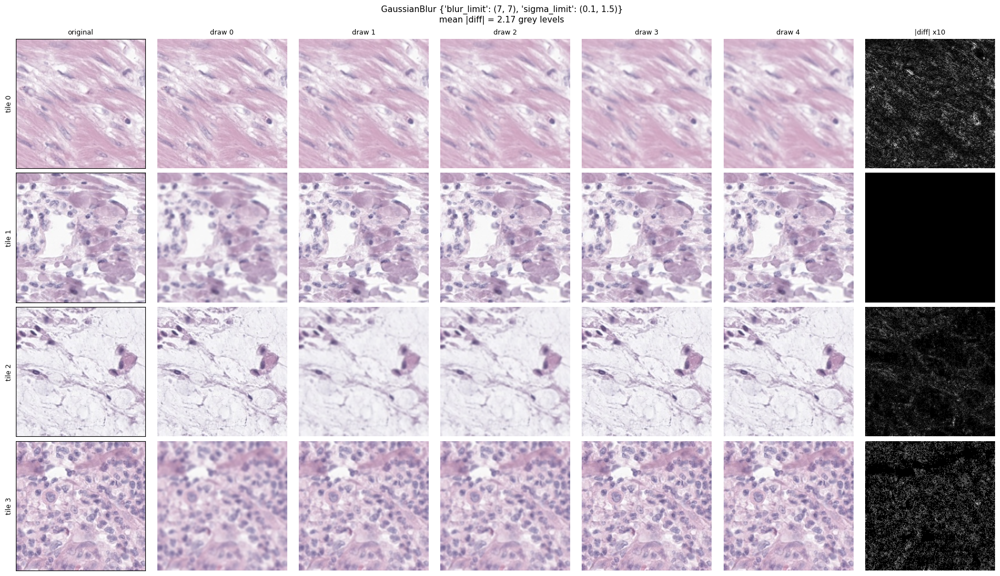

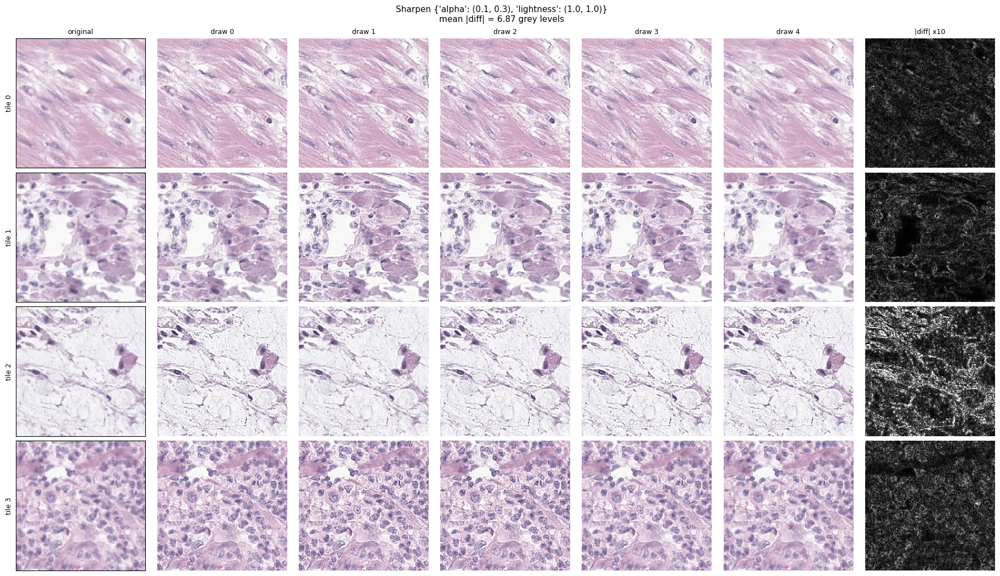

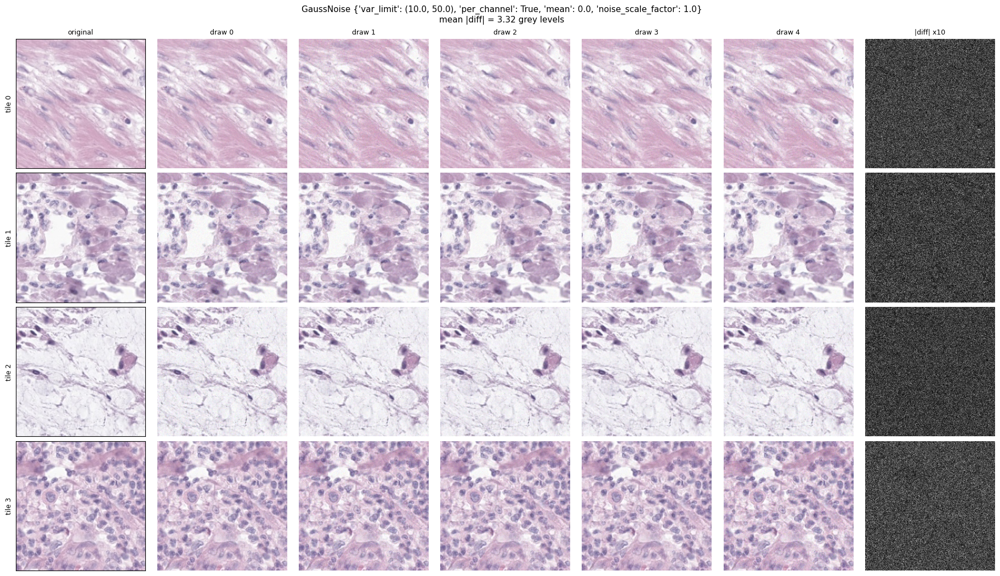

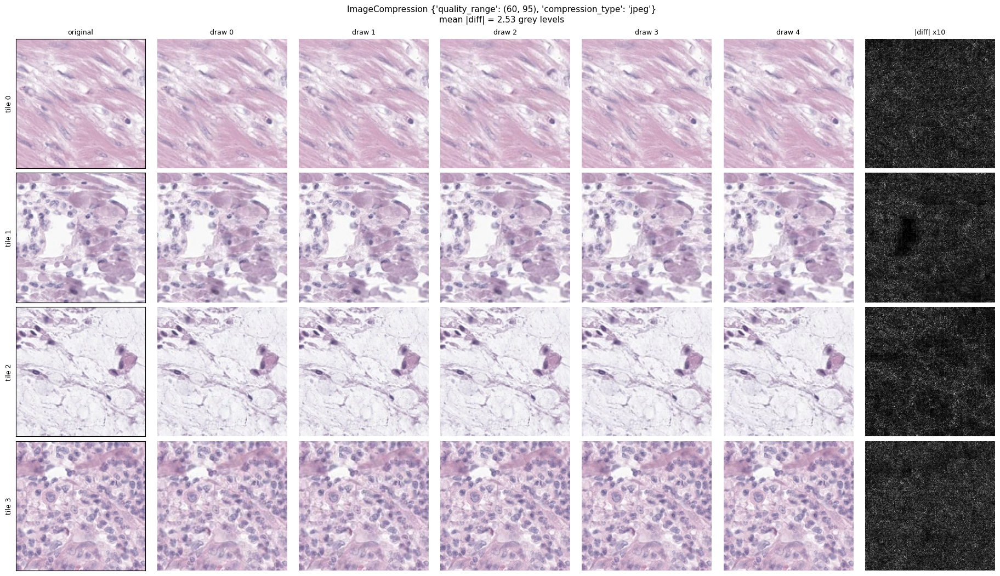

In [21]:
catalogue_args = Namespace(**vars(args))
catalogue_args.augment = True
for name in AUGMENTATION_PROBABILITIES:
    setattr(catalogue_args, name, 1.0)
catalogue = build_augmentations(catalogue_args, training=True)

for transform in catalogue.transforms:
    seed_everything(SEED)
    rows, differences = [], []
    for tile in tiles:
        draws = [transform(image=tile)["image"] for _ in range(N_DRAWS)]
        differences += [mean_absolute_difference(tile, draw) for draw in draws]
        rows.append([tile, *draws, difference_map(tile, draws[-1])])
    parameters = {
        key: value
        for key, value in transform.get_base_init_args().items()
        if key not in ("p", "always_apply")
    }
    parameters.update(transform.get_transform_init_args())
    show_grid(
        rows,
        row_titles=[f"tile {i}" for i in range(N_TILES)],
        column_titles=["original", *[f"draw {i}" for i in range(N_DRAWS)], "|diff| x10"],
        suptitle=(
            f"{type(transform).__name__} {parameters}\n"
            f"mean |diff| = {np.mean(differences):.2f} grey levels"
        ),
    )

## 5. Spatial: the 8 orientations

Flips and 90 degree rotations generate the 8 symmetries of the square
(dihedral group D4): every cell stays in the tile, so the target is
unchanged. `Transpose` would add nothing.

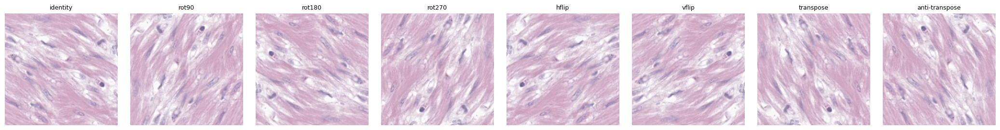

In [6]:
tile = tiles[0]
orientations = {
    "identity": tile,
    "rot90": np.rot90(tile, 1),
    "rot180": np.rot90(tile, 2),
    "rot270": np.rot90(tile, 3),
    "hflip": tile[:, ::-1],
    "vflip": tile[::-1],
    "transpose": tile.transpose(1, 0, 2),
    "anti-transpose": np.rot90(tile, 2).transpose(1, 0, 2),
}
show_grid(
    [list(orientations.values())],
    column_titles=list(orientations),
)

## 6. HED stain jitter

`HEDStainAugment`: optical density -> H / E / DAB concentrations (fixed
Ruifrok & Johnston vectors) -> `C' = alpha * C + beta` on H and E, on tissue
pixels only (max OD > `od_threshold`) -> back to RGB.

### 6.1 Decomposition and tissue mask

Check that the fixed stain vectors separate the stains on these tiles:
nuclei in H, cytoplasm / stroma in E, little structure in DAB (residual).
Pixels outside the mask (shown black) are never changed.

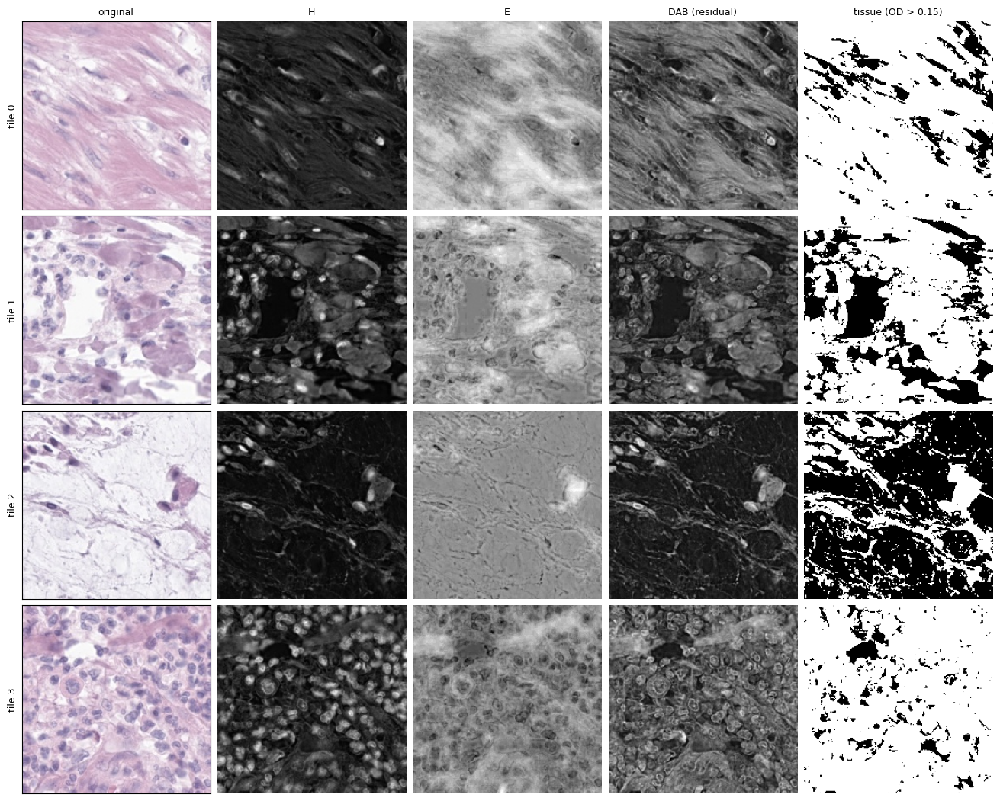

In [22]:
rows = []
for tile in tiles:
    concentrations, tissue = stain_concentrations(tile, args.hed_od_threshold)
    rows.append(
        [
            tile,
            concentrations[..., 0],
            concentrations[..., 1],
            concentrations[..., 2],
            (tissue * 255).astype(np.uint8),
        ]
    )
show_grid(
    rows,
    row_titles=[f"tile {i}" for i in range(N_TILES)],
    column_titles=[
        "original",
        "H",
        "E",
        "DAB (residual)",
        f"tissue (OD > {args.hed_od_threshold})",
    ],
)

### 6.2 Background threshold

Distribution of the per-pixel max optical density over the cohort sample.
Glass sits in a narrow peak near 0; `hed_od_threshold` should fall between
that peak and pale tissue (stroma, fat borders). Pixels below it are not
jittered.

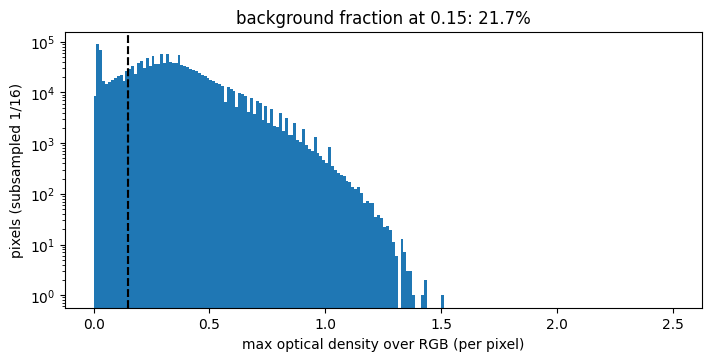

In [8]:
rng = np.random.default_rng(SEED)
cohort_paths = [
    tile_paths[i]
    for i in rng.choice(len(tile_paths), min(N_COHORT_TILES, len(tile_paths)), replace=False)
]
cohort_tiles = [load_tile(path) for path in cohort_paths]

max_optical_density = np.concatenate(
    [
        (-np.log((tile.reshape(-1, 3).astype(np.float32) + 1.0) / 256.0)).max(axis=1)[::16]
        for tile in cohort_tiles
    ]
)

fig, axis = plt.subplots(figsize=(7, 3.5), layout="constrained")
axis.hist(max_optical_density, bins=200, range=(0, 2.5), log=True)
for threshold, style in ((0.15, ":"), (args.hed_od_threshold, "--")):
    axis.axvline(threshold, color="k", linestyle=style)
axis.set_xlabel("max optical density over RGB (per pixel)")
axis.set_ylabel("pixels (subsampled 1/16)")
axis.set_title(
    f"background fraction at {args.hed_od_threshold}: "
    f"{(max_optical_density <= args.hed_od_threshold).mean():.1%}"
)
plt.show()

### 6.3 `sigma_alpha` sweep (stain amount)

Deterministic extremes of the multiplicative jitter (`beta = 0`): both stains
lighter / darker, and H vs E imbalance. Rows are `sigma_alpha` values; the
largest values show where tiles start to look unrealistic.

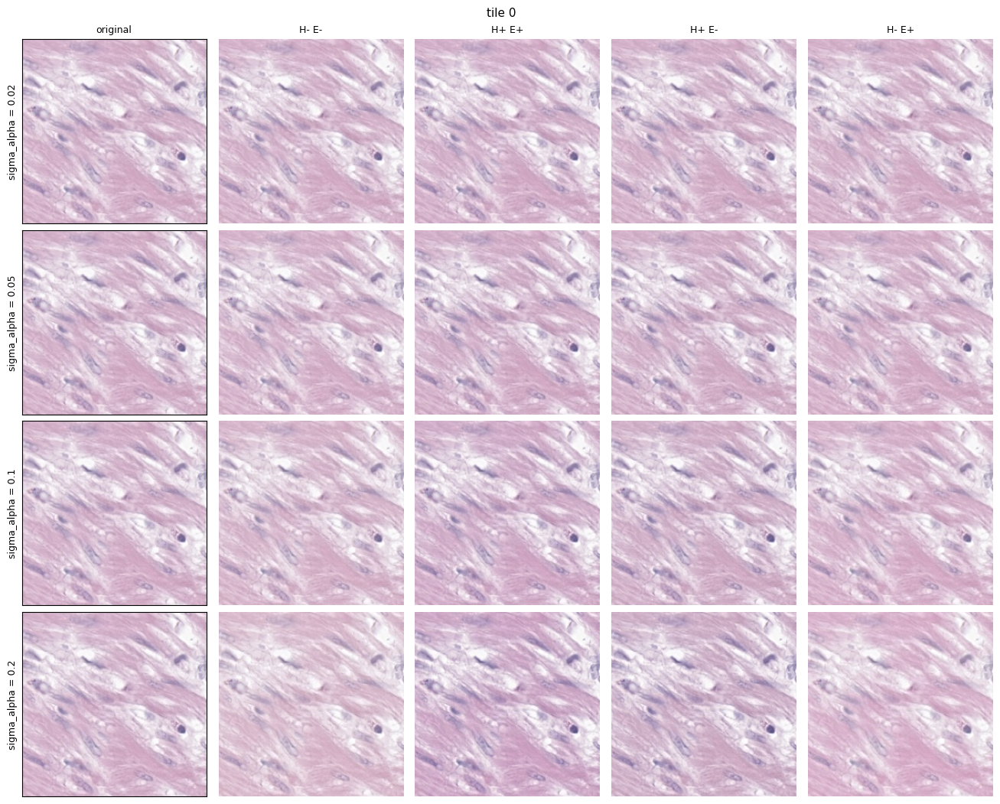

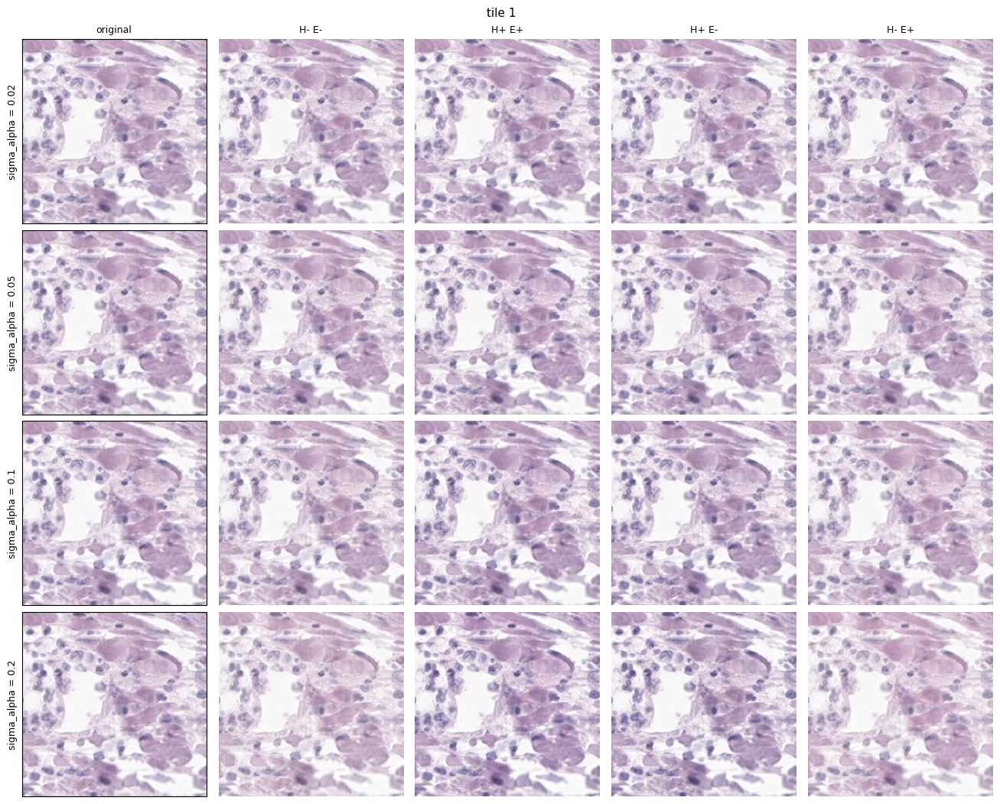

In [9]:
SIGMA_ALPHAS = [0.02, 0.05, 0.1, 0.2]

def alpha_corners(sigma):
    return {
        "H- E-": (1 - sigma, 1 - sigma),
        "H+ E+": (1 + sigma, 1 + sigma),
        "H+ E-": (1 + sigma, 1 - sigma),
        "H- E+": (1 - sigma, 1 + sigma),
    }

for tile_index in range(min(2, N_TILES)):
    tile = tiles[tile_index]
    rows = [
        [tile, *[hed_jitter(tile, alpha, od_threshold=args.hed_od_threshold) for alpha in alpha_corners(sigma).values()]]
        for sigma in SIGMA_ALPHAS
    ]
    show_grid(
        rows,
        row_titles=[f"sigma_alpha = {sigma}" for sigma in SIGMA_ALPHAS],
        column_titles=["original", *alpha_corners(0).keys()],
        suptitle=f"tile {tile_index}",
    )

### 6.4 `sigma_beta` sweep (additive shift)

Deterministic extremes of the additive jitter (`alpha = 1`). `beta` adds or
removes stain uniformly on tissue pixels, so it changes pale regions most;
the tissue mask keeps the glass white. Disabled by default
(`hed_sigma_beta = 0`).

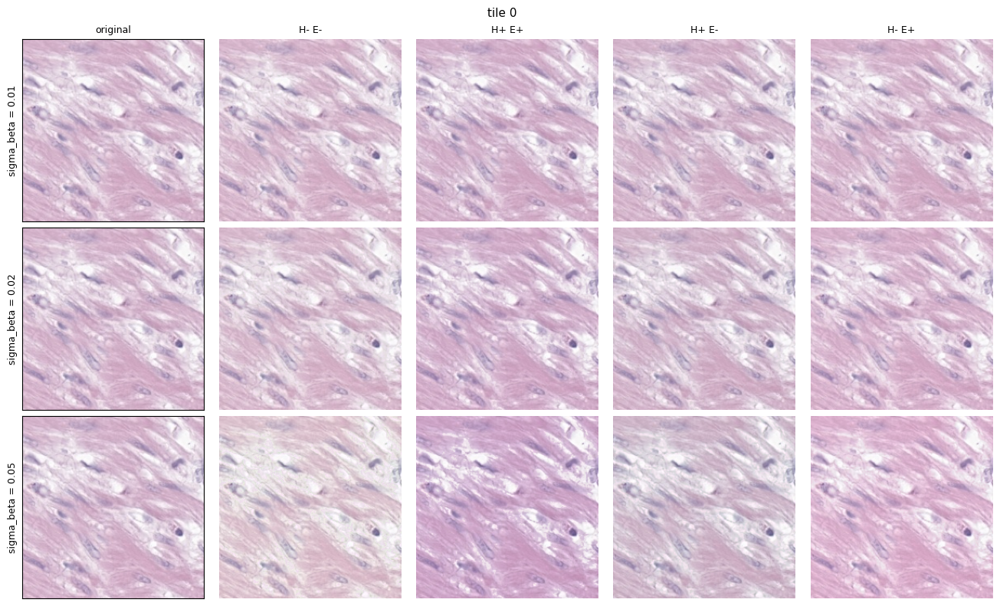

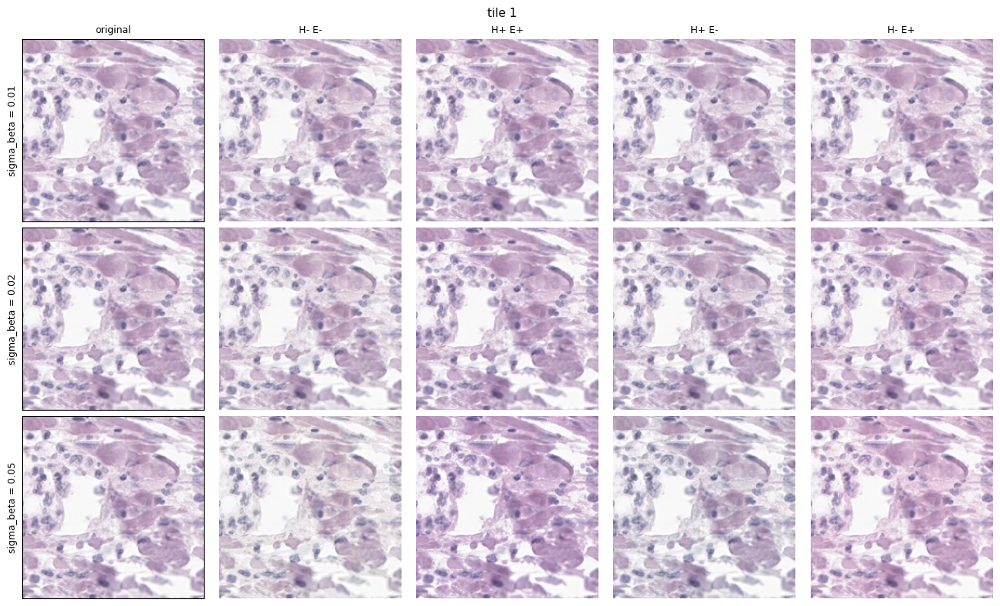

In [10]:
SIGMA_BETAS = [0.01, 0.02, 0.05]

def beta_corners(sigma):
    return {
        "H- E-": (-sigma, -sigma),
        "H+ E+": (sigma, sigma),
        "H+ E-": (sigma, -sigma),
        "H- E+": (-sigma, sigma),
    }

for tile_index in range(min(2, N_TILES)):
    tile = tiles[tile_index]
    rows = [
        [
            tile,
            *[
                hed_jitter(tile, (1.0, 1.0), beta, od_threshold=args.hed_od_threshold)
                for beta in beta_corners(sigma).values()
            ],
        ]
        for sigma in SIGMA_BETAS
    ]
    show_grid(
        rows,
        row_titles=[f"sigma_beta = {sigma}" for sigma in SIGMA_BETAS],
        column_titles=["original", *beta_corners(0).keys()],
        suptitle=f"tile {tile_index}",
    )

### 6.5 Realism: augmented tiles vs the cohort color distribution

Each grey point is one cohort tile: mean H and E concentration over its
tissue pixels. Colored clouds are `N_JITTER_DRAWS` random HED jitters of the
displayed tiles (configured `hed_sigma_alpha` / `hed_sigma_beta`), the cross
marks the original. Jitters that stay inside the grey cloud reproduce color
variation already present in the cohort; jitters far outside it are colors
the model will never see at test time on this cohort (useful only for
robustness to other cohorts, at the risk of unrealistic tiles).

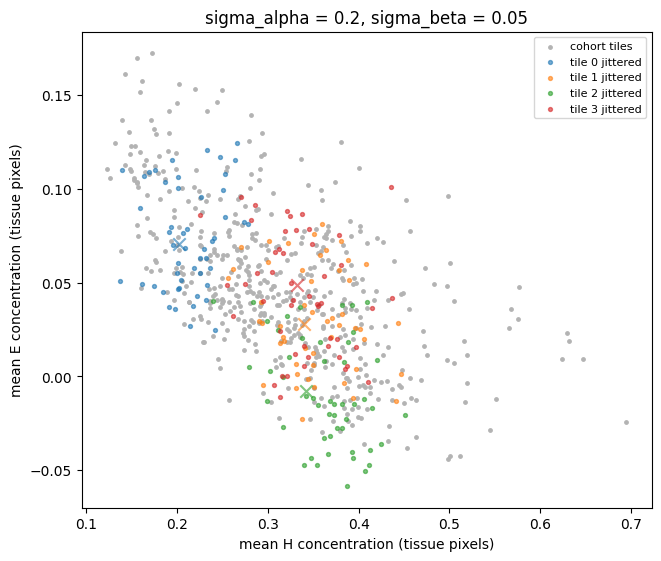

,count,mean,std,min,25%,50%,75%,max
H,500.0,0.314480,0.097504,0.123219,0.246985,0.308520,0.381472,0.694386
E,500.0,0.048504,0.041328,-0.044193,0.021063,0.044954,0.073083,0.172327


In [23]:
N_JITTER_DRAWS = 50

def mean_stains(image, od_threshold):
    concentrations, tissue = stain_concentrations(image, od_threshold)
    if not tissue.any():
        return np.full(2, np.nan)
    return concentrations[tissue][:, :2].mean(axis=0)

cohort_stains = np.array([mean_stains(tile, args.hed_od_threshold) for tile in cohort_tiles])

jitter = HEDStainAugment(
    sigma_alpha=args.hed_sigma_alpha,
    sigma_beta=args.hed_sigma_beta,
    od_threshold=args.hed_od_threshold,
    p=1.0,
)
seed_everything(SEED)

fig, axis = plt.subplots(figsize=(6.5, 5.5), layout="constrained")
axis.scatter(cohort_stains[:, 0], cohort_stains[:, 1], s=6, color="0.7", label="cohort tiles")
for tile_index, tile in enumerate(tiles):
    jittered = np.array(
        [mean_stains(jitter(image=tile)["image"], args.hed_od_threshold) for _ in range(N_JITTER_DRAWS)]
    )
    points = axis.scatter(jittered[:, 0], jittered[:, 1], s=8, alpha=0.6, label=f"tile {tile_index} jittered")
    original = mean_stains(tile, args.hed_od_threshold)
    axis.scatter(*original, marker="x", s=80, color=points.get_facecolor()[0])
axis.set_xlabel("mean H concentration (tissue pixels)")
axis.set_ylabel("mean E concentration (tissue pixels)")
axis.set_title(
    f"sigma_alpha = {args.hed_sigma_alpha}, sigma_beta = {args.hed_sigma_beta}"
)
axis.legend(fontsize=8)
plt.show()

pd.DataFrame(cohort_stains, columns=["H", "E"]).describe().T

## 7. Training pipeline

The pipeline used by `HETileDataset` at training time, with the configured
probabilities (`OVERRIDES` included). Each column is one independent pass,
as seen by the model across epochs.

Compose([
  HorizontalFlip(p=0.5),
  VerticalFlip(p=0.5),
  RandomRotate90(p=0.5),
  HEDStainAugment(p=0.5, sigma_alpha=0.2, sigma_beta=0.05, od_threshold=0.15),
  RandomBrightnessContrast(p=0.5, brightness_limit=(-0.2, 0.2), contrast_limit=(-0.2, 0.2), brightness_by_max=True),
  GaussianBlur(p=0.1, blur_limit=(7, 7), sigma_limit=(0.1, 1.5)),
  Sharpen(p=0.1, alpha=(0.1, 0.3), lightness=(1.0, 1.0)),
  GaussNoise(p=0.1, var_limit=(10.0, 50.0), per_channel=True, mean=0.0, noise_scale_factor=1.0),
  ImageCompression(p=0.1, quality_range=(60, 95), compression_type='jpeg'),
], p=1.0, bbox_params=None, keypoint_params=None, additional_targets={}, is_check_shapes=True)


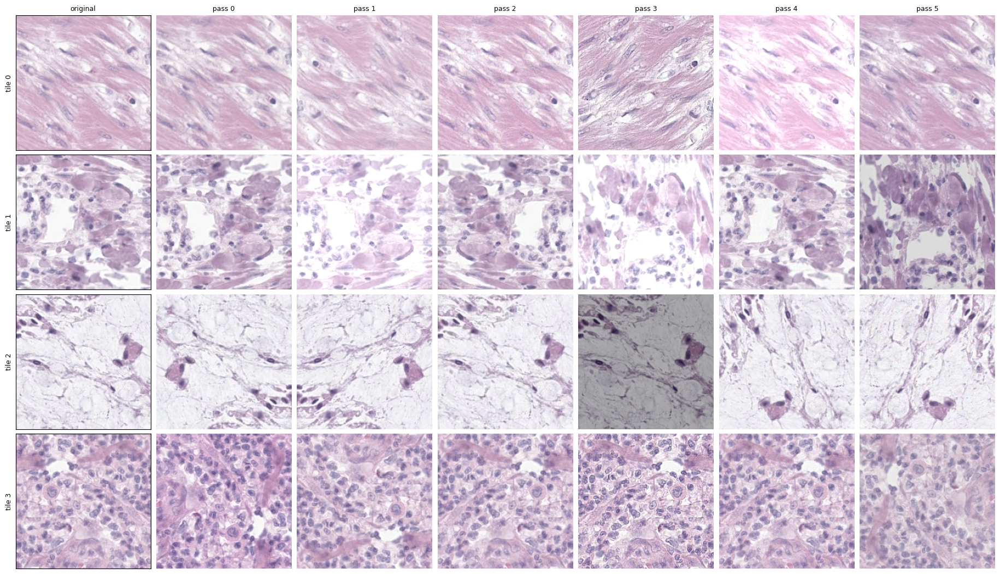

In [25]:
pipeline = build_augmentations(args, training=True)
if pipeline is None:
    print("Augmentations disabled (`augment=False`).")
else:
    print(pipeline)
    seed_everything(SEED)
    show_grid(
        [[tile, *[pipeline(image=tile)["image"] for _ in range(N_DRAWS + 1)]] for tile in tiles],
        row_titles=[f"tile {i}" for i in range(N_TILES)],
        column_titles=["original", *[f"pass {i}" for i in range(N_DRAWS + 1)]],
    )